##### **Błażej Klepacki, 331389**

In [1]:
import gudhi
import numpy as np
import galois
import itertools
import matplotlib.pyplot as plt
from math import comb
from time import perf_counter

##### Funkcje z Lab4: macierz brzegu, f, r, betti

In [2]:
def simplices(st, k):
    return sorted(tuple(s) for s, _ in st.get_skeleton(k) if len(s) == k + 1)

def boundary_matrix(st, k, p=2):
    cols = simplices(st, k)
    rows = simplices(st, k - 1)
    index = {tau: i for i, tau in enumerate(rows)}
    D = np.zeros((len(index), len(cols)), dtype=int)

    for j, sigma in enumerate(cols):
        for i in range(len(sigma)):
            tau = sigma[:i] + sigma[i + 1:]
            D[index[tau], j] = (-1) ** i % p
    return D

In [3]:
def f(sk, i):
    return len(simplices(sk, i))

In [4]:
def r(st, k, p=2):
    if k <= 0 or k > st.dimension():
        return 0
    GF2 = galois.GF(p)
    return np.linalg.matrix_rank(GF2(boundary_matrix(st, k, p)))

In [5]:
def betti(sk, p=2):
    return [f(sk, i) - r(sk, i, p) - r(sk, i+1, p) for i in range(3)]

##### Chmury z wykładu

$n$ punktów $(\cos t_j, \sin t_j) + \varepsilon_j$, $t_j$ jednostajnie z $[0, 2\pi)$, $\varepsilon_j \sim N(0, \sigma^2 I_2)$. najpierw losuję wszystkie $t_j$, potem szum, przy takiej kolejności dla (A) wychodzi to samo $f$ co na wykładzie 5 (sprawdzenie niżej)

In [6]:
def chmura(n, sigma, seed=0):
    rng = np.random.default_rng(seed)
    t = rng.uniform(0, 2 * np.pi, n)
    return np.c_[np.cos(t), np.sin(t)] + rng.normal(0, sigma, (n, 2))

XA = chmura(60, 0.05)    # (A) z wykladu 5
XB = chmura(120, 0.1)    # (B) z wykladu 1

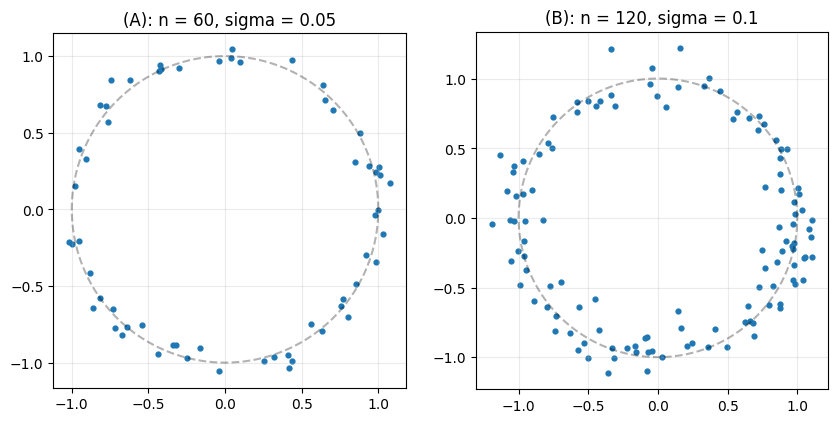

In [7]:
s = np.linspace(0, 2 * np.pi, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, X, tytul in [(axes[0], XA, '(A): n = 60, sigma = 0.05'), (axes[1], XB, '(B): n = 120, sigma = 0.1')]:
    ax.plot(np.cos(s), np.sin(s), 'k--', alpha=0.3)
    ax.scatter(X[:, 0], X[:, 1], s=12)
    ax.set_aspect('equal')
    ax.set_title(tytul)
    ax.grid(alpha=0.25)
plt.show()

##### Najmniejsza kula

z lematu o najmniejszej kuli $\sigma \in \check{C}_r(X) \iff \rho(\sigma) < r$, a budujemy tylko sympleksy wymiaru $\le 2$, więc wystarczą trzy przypadki z wykładu:
* wierzchołek: $\rho = 0$
* krawędź: $\rho = \frac{1}{2}\|x - x'\|$
* trójkąt rozwartokątny (albo prostokątny): $\rho = \frac{1}{2}$ najdłuższego boku
* trójkąt ostrokątny: promień okręgu opisanego $R = \frac{abc}{4S}$, pole $S$ ze wzoru Herona

rozwartokątny sprawdzam z tw. cosinusów: dla najdłuższego boku $c$ kąt naprzeciwko jest $\ge 90^\circ \iff c^2 \ge a^2 + b^2$. trójkąt z trzema punktami na jednej prostej też tu wpada ($c = a + b$), więc nie dzielimy przez $S = 0$

In [8]:
def rho(P):
    # promien najmniejszej kuli zawierajacej punkty P (1, 2 albo 3 punkty)
    if len(P) == 1:
        return 0.
    if len(P) == 2:
        return np.linalg.norm(P[0] - P[1]) / 2

    a, b, c = sorted([np.linalg.norm(P[0] - P[1]),
                      np.linalg.norm(P[1] - P[2]),
                      np.linalg.norm(P[0] - P[2])])
    if c**2 >= a**2 + b**2:     # rozwartokatny / prostokatny
        return c / 2
    p = (a + b + c) / 2
    S = np.sqrt(p * (p - a) * (p - b) * (p - c))    # Heron
    return a * b * c / (4 * S)                      # okrag opisany

##### **Zadanie 1**

najprostsza wersja: sprawdzam wszystkie podzbiory 1-, 2- i 3-elementowe i wstawiam te, dla których $\rho < r$. `insert` wstawia też ściany, ale to nic nie psuje, bo ściany sympleksu Čecha też są w kompleksie

In [9]:
def cech(X, r):
    st = gudhi.SimplexTree()
    for k in range(1, 4):
        for sigma in itertools.combinations(range(len(X)), k):
            if rho(X[list(sigma)]) < r:
                st.insert(list(sigma))
    return st

sprawdzenie na przykładach z wykładu:
* trójkąt równoboczny o boku $a = 1$: dla $r \le 1/2$ ma być $\beta = (3, 0)$, dla $1/2 < r \le 1/\sqrt{3} \approx 0.577$ ma być $(1, 1)$, a dla większych $(1, 0)$
* chmura (A), $r = 0.3$: na wykładzie $f = (60, 332, 835)$, $\beta = (1, 1)$

przy okazji pierwsze wywołanie `betti` kompiluje kod w galois, więc te liczenia robią też za rozgrzewkę przed pomiarami

In [10]:
trojkat = np.array([[0, 0], [1, 0], [0.5, np.sqrt(3) / 2]])
for rr in [0.45, 0.55, 0.6]:
    print(f'trojkat, r = {rr}: beta = {betti(cech(trojkat, rr))[:2]}')

K = cech(XA, 0.3)
print(f'chmura (A), r = 0.3: f = {K.num_simplices_by_dimension()}, beta = {betti(K)[:2]}')

trojkat, r = 0.45: beta = [3, 0]
trojkat, r = 0.55: beta = [1, 1]
trojkat, r = 0.6: beta = [1, 0]
chmura (A), r = 0.3: f = [ 60 332 835], beta = [1, 1]


zgadza się z wykładem. dalej wypisuję tylko $\beta_0, \beta_1$, bo $\beta_2$ kompleksu obciętego do trójkątów nie ma sensu (nie ma czworościanów, więc $r_3 = 0$ i każdy 2-cykl liczy się jako dziura)

**zadanie 1a**

In [11]:
def pomiar(X, r):
    start = perf_counter()
    K = cech(X, r)
    t_bud = perf_counter() - start

    start = perf_counter()
    b = betti(K)
    t_bet = perf_counter() - start

    return [f(K, 0), f(K, 1), f(K, 2)], b[0], b[1], t_bud, t_bet


def tabela(X, rs):
    wyniki = []
    for rr in rs:
        fv, b0, b1, t_bud, t_bet = pomiar(X, rr)
        wyniki.append((rr, fv, b0, b1, t_bud, t_bet))
        print(f'r = {rr:.2f} | f = {str(fv):20} | beta0 = {b0:3}, beta1 = {b1:2} | '
              f'budowa: {t_bud:.3f} s | betti: {t_bet:.3f} s')
    return wyniki

In [12]:
rs_A = np.round(np.arange(0.05, 1.21, 0.05), 2)
wyniki_A = tabela(XA, rs_A)

r = 0.05 | f = [60, 37, 9]          | beta0 =  31, beta1 =  0 | budowa: 0.674 s | betti: 0.011 s
r = 0.10 | f = [60, 91, 58]         | beta0 =  10, beta1 =  0 | budowa: 0.636 s | betti: 0.022 s
r = 0.15 | f = [60, 144, 146]       | beta0 =   3, beta1 =  0 | budowa: 0.882 s | betti: 0.042 s
r = 0.20 | f = [60, 205, 298]       | beta0 =   1, beta1 =  1 | budowa: 0.648 s | betti: 0.058 s
r = 0.25 | f = [60, 265, 515]       | beta0 =   1, beta1 =  1 | budowa: 0.479 s | betti: 0.067 s
r = 0.30 | f = [60, 332, 835]       | beta0 =   1, beta1 =  1 | budowa: 0.571 s | betti: 0.084 s
r = 0.35 | f = [60, 394, 1183]      | beta0 =   1, beta1 =  1 | budowa: 0.546 s | betti: 0.128 s
r = 0.40 | f = [60, 443, 1514]      | beta0 =   1, beta1 =  1 | budowa: 0.576 s | betti: 0.133 s
r = 0.45 | f = [60, 496, 1900]      | beta0 =   1, beta1 =  1 | budowa: 0.501 s | betti: 0.155 s
r = 0.50 | f = [60, 570, 2533]      | beta0 =   1, beta1 =  1 | budowa: 0.514 s | betti: 0.187 s
r = 0.55 | f = [60, 634, 3147]

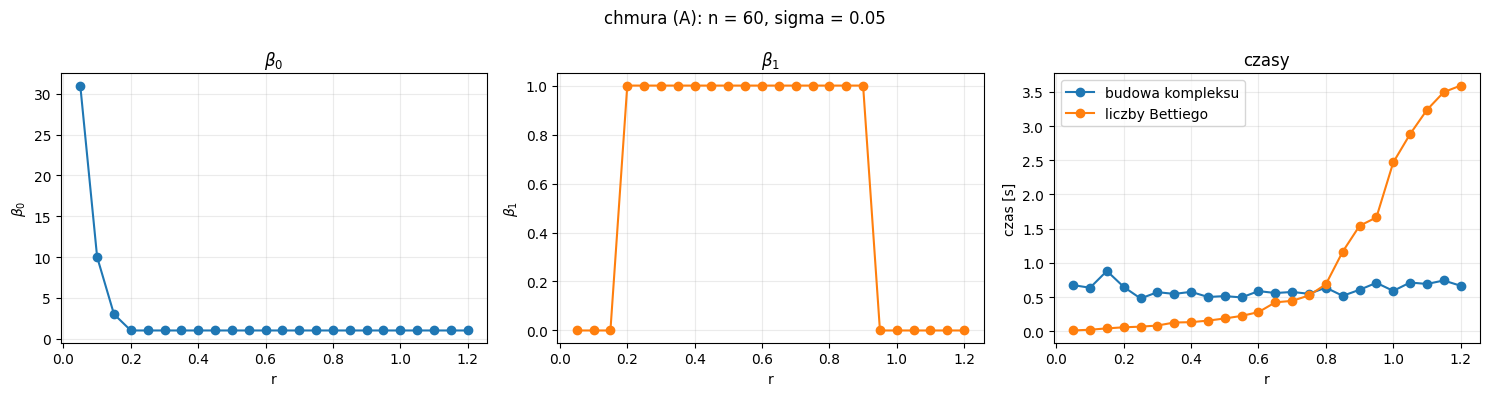

In [13]:
def rysuj(wyniki, tytul):
    rs = [w[0] for w in wyniki]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(rs, [w[2] for w in wyniki], 'o-')
    axes[0].set(xlabel='r', ylabel=r'$\beta_0$', title=r'$\beta_0$')
    axes[1].plot(rs, [w[3] for w in wyniki], 'o-', color='C1')
    axes[1].set(xlabel='r', ylabel=r'$\beta_1$', title=r'$\beta_1$')
    axes[2].plot(rs, [w[4] for w in wyniki], 'o-', label='budowa kompleksu')
    axes[2].plot(rs, [w[5] for w in wyniki], 'o-', label='liczby Bettiego')
    axes[2].set(xlabel='r', ylabel='czas [s]', title='czasy')
    axes[2].legend()

    for ax in axes:
        ax.grid(alpha=0.25)
    fig.suptitle(tytul)
    fig.tight_layout()
    plt.show()

rysuj(wyniki_A, 'chmura (A): n = 60, sigma = 0.05')

czas budowy jest prawie stały (ok. 0.25 s) dla każdego $r$, bo `cech` zawsze sprawdza te same 36050 podzbiorów, a $r$ zmienia tylko wynik testu $\rho < r$. czas liczenia liczb Bettiego rośnie z $r$ od 0.008 s do ok. 1.7 s, razem z $f$: większe $r$ to więcej krawędzi i trójkątów, czyli większe macierze brzegu. od $r = 1.15$ jest $f = (60, 1770, 34220)$, czyli wszystkie pary i trójki ($\binom{60}{2} = 1770$, $\binom{60}{3} = 34220$), kompleks to cały 2-szkielet sympleksu i czas betti przestaje rosnąć

**zadanie 1b**

szukam przedziału $r$, dla którego $\beta = (1, 1)$. dla porównania liczę też dwie rzeczy z wykładu:
* jak daleko od chmury jest najdalszy punkt okręgu (jak w przykładzie z 24-kątem). twierdzenie (NSW + nerw) wymaga, żeby to było $< r/2$, i $r < \sqrt{3/5}\,\tau$, gdzie dla okręgu jednostkowego $\tau = 1$. formalnie nie działa, bo punkty nie leżą na okręgu, ale daje jakiś punkt odniesienia
* od jakiego $r$ w kompleksie jest trójkąt, który zawiera środek okręgu $(0, 0)$. dopóki takiego nie ma, trójkąty nie mają szans zakleić dziury w środku

In [14]:
def okno(wyniki):
    # r, dla ktorych beta = (1, 1)
    return [float(w[0]) for w in wyniki if w[2] == 1 and w[3] == 1]


def najdalszy_punkt_okregu(X, m=10000):
    # odleglosc najdalszego punktu okregu od chmury (okrag przyblizony m punktami)
    s = np.linspace(0, 2 * np.pi, m, endpoint=False)
    M = np.c_[np.cos(s), np.sin(s)]
    odl = np.linalg.norm(M[:, None, :] - X[None, :, :], axis=2)
    return odl.min(axis=1).max()


def zawiera_srodek(P):
    # (0, 0) jest w trojkacie, gdy iloczyny wektorowe kolejnych wierzcholkow maja ten sam znak
    c = [P[i][0] * P[(i + 1) % 3][1] - P[i][1] * P[(i + 1) % 3][0] for i in range(3)]
    return all(x > 0 for x in c) or all(x < 0 for x in c)


okno_A = okno(wyniki_A)
d_A = najdalszy_punkt_okregu(XA)
rho_srodek_A = min(rho(XA[list(t)]) for t in itertools.combinations(range(len(XA)), 3)
                   if zawiera_srodek(XA[list(t)]))

print(f'beta = (1, 1) dla r od {min(okno_A)} do {max(okno_A)}: {okno_A}')
print(f'najdalszy punkt okregu jest {d_A:.3f} od chmury, wiec warunek gestosci daje r > {2 * d_A:.3f}')
print(f'gorne ograniczenie z twierdzenia: r < sqrt(3/5) = {np.sqrt(3 / 5):.3f}')
print(f'najmniejsze rho trojkata zawierajacego srodek: {rho_srodek_A:.3f}')

beta = (1, 1) dla r od 0.2 do 0.9: [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]
najdalszy punkt okregu jest 0.183 od chmury, wiec warunek gestosci daje r > 0.367
gorne ograniczenie z twierdzenia: r < sqrt(3/5) = 0.775
najmniejsze rho trojkata zawierajacego srodek: 0.924


**Wnioski do zadania 1b**

- kompleks "widzi" okrąg, czyli $\beta = (1, 1)$, dla $r$ od 0.20 do 0.90 (z dokładnością do kroku 0.05)
- poniżej, dla $r = 0.05, 0.10, 0.15$, jest $\beta_0 = 31, 10, 3$ i $\beta_1 = 0$. kule są za małe, żeby połączyć wszystkich sąsiadów, więc chmura rozpada się na kawałki łuków i pętla się nie zamyka. najdalszy punkt okręgu jest 0.183 od chmury, czyli największa przerwa między sąsiednimi punktami ma mniej więcej $2 \cdot 0.183 \approx 0.37$, a krawędź jest, gdy odległość $< 2r$. przerwa zamyka się więc przy $r \approx 0.18$, co pasuje do skoku między 0.15 a 0.20
- powyżej, od $r = 0.95$, $\beta_1 = 0$: dziura w środku jest zaklejona trójkątami. najmniejsze $\rho$ trójkąta zawierającego $(0, 0)$ wynosi 0.924, czyli dokładnie między 0.90 a 0.95, tam gdzie $\beta_1$ spada. intuicyjnie kule zaczynają sięgać środka okręgu (punkty są w odległości ok. 1 od środka). $\beta_0 = 1$ zostaje do końca, więc kompleks zachowuje się jak dysk, a nie okrąg
- twierdzenie z wykładu daje przedział $(0.367, 0.775)$ i on się mieści w tym, co wyszło. ale prawdziwy przedział jest dużo szerszy: twierdzenie to warunek wystarczający, a nie konieczny. dolna granica wymaga, żeby każdy punkt okręgu był bliżej niż $r/2$, a pętla zamyka się już, gdy kule sąsiadów się przecinają. do tego formalnie twierdzenie nie działa, bo punkty mają szum, a i tak wychodzi dobrze (tak jak na wykładzie dla $r = 0.3$)
- w praktyce nie znamy $\tau$ ani gęstości próbki, więc nie wiadomo z góry, które $r$ wziąć. tu przedział jest szeroki, więc łatwo trafić, ale to jest właśnie problem, który wykład zostawia na persystencję

**zadanie 1c**

In [15]:
rs_B = np.round(np.arange(0.05, 0.51, 0.05), 2)
wyniki_B = tabela(XB, rs_B)

r = 0.05 | f = [120, 79, 18]        | beta0 =  57, beta1 =  0 | budowa: 4.483 s | betti: 0.022 s
r = 0.10 | f = [120, 315, 375]      | beta0 =   4, beta1 =  2 | budowa: 5.407 s | betti: 0.097 s
r = 0.15 | f = [120, 622, 1620]     | beta0 =   2, beta1 =  1 | budowa: 4.562 s | betti: 0.199 s
r = 0.20 | f = [120, 889, 3369]     | beta0 =   1, beta1 =  1 | budowa: 3.856 s | betti: 0.286 s
r = 0.25 | f = [120, 1183, 6021]    | beta0 =   1, beta1 =  1 | budowa: 4.194 s | betti: 0.685 s
r = 0.30 | f = [120, 1425, 8791]    | beta0 =   1, beta1 =  1 | budowa: 4.210 s | betti: 0.875 s
r = 0.35 | f = [120, 1671, 12103]   | beta0 =   1, beta1 =  1 | budowa: 4.173 s | betti: 1.556 s
r = 0.40 | f = [120, 1929, 15976]   | beta0 =   1, beta1 =  1 | budowa: 3.817 s | betti: 1.785 s
r = 0.45 | f = [120, 2193, 20518]   | beta0 =   1, beta1 =  1 | budowa: 4.161 s | betti: 2.581 s
r = 0.50 | f = [120, 2454, 25686]   | beta0 =   1, beta1 =  1 | budowa: 4.061 s | betti: 3.223 s


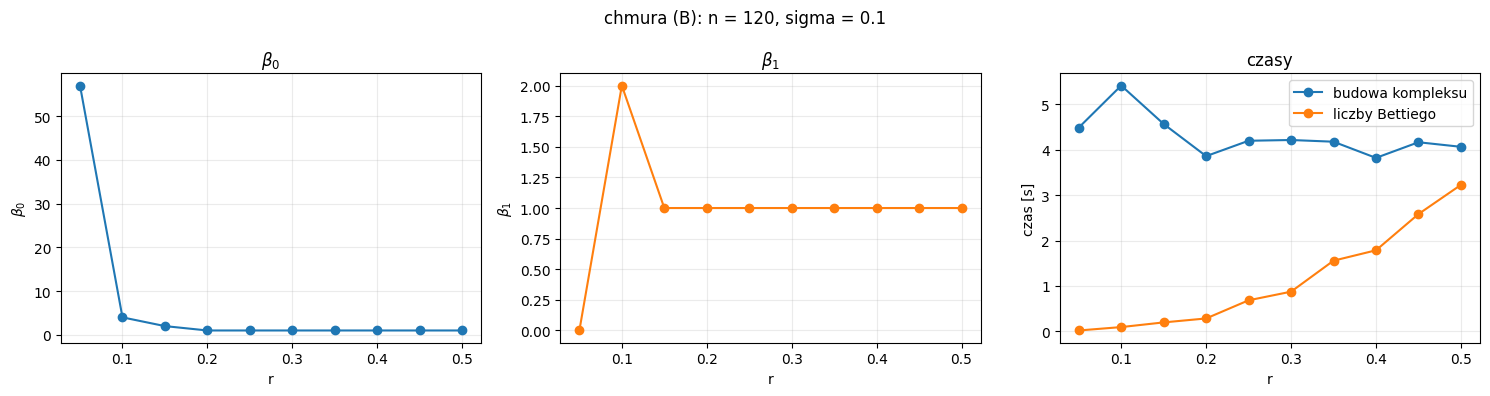

In [16]:
rysuj(wyniki_B, 'chmura (B): n = 120, sigma = 0.1')

In [17]:
okno_B = okno(wyniki_B)
d_B = najdalszy_punkt_okregu(XB)

print(f'beta = (1, 1) dla r: {okno_B}')
print(f'najdalszy punkt okregu jest {d_B:.3f} od chmury, wiec warunek gestosci daje r > {2 * d_B:.3f}')

beta = (1, 1) dla r: [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]
najdalszy punkt okregu jest 0.155 od chmury, wiec warunek gestosci daje r > 0.309


dla $r = 0.15$ wychodzi $\beta_0 = 2$, ale $\beta_1 = 1$, więc sprawdzam, czy to jest okrąg plus coś osobno. szukam wierzchołków bez żadnej krawędzi (jak w Lab4 przez `get_cofaces`). do tego to samo co w (A): najmniejsze $\rho$ trójkąta zawierającego środek, czyli mniej więcej gdzie skończyłby się przedział, gdyby iść z $r$ dalej

In [18]:
for rr in [0.10, 0.15]:
    K = cech(XB, rr)
    samotne = [v for (v,) in simplices(K, 0) if len(K.get_cofaces([v], 1)) == 0]
    print(f'r = {rr}: beta = {betti(K)[:2]}, punkty bez krawedzi: {samotne}, '
          f'ich odleglosc od (0, 0): {[round(float(np.linalg.norm(XB[v])), 3) for v in samotne]}')

rho_srodek_B = min(rho(XB[list(t)]) for t in itertools.combinations(range(len(XB)), 3)
                   if zawiera_srodek(XB[list(t)]))
print(f'najmniejsze rho trojkata zawierajacego srodek: {rho_srodek_B:.3f}')
print(f'najblizszy srodka punkt: (A) {np.linalg.norm(XA, axis=1).min():.3f}, (B) {np.linalg.norm(XB, axis=1).min():.3f}')

r = 0.1: beta = [4, 2], punkty bez krawedzi: [46, 64], ich odleglosc od (0, 0): [1.231, 1.256]
r = 0.15: beta = [2, 1], punkty bez krawedzi: [64], ich odleglosc od (0, 0): [1.256]
najmniejsze rho trojkata zawierajacego srodek: 0.750
najblizszy srodka punkt: (A) 0.905, (B) 0.682


**Wnioski do zadania 1**

- dla (B) $\beta = (1, 1)$ dla $r$ od 0.20 do 0.50, górnego końca nie widać, bo liczymy tylko do 0.5
- poniżej jest inaczej niż w (A). dla $r = 0.10$ wychodzi $\beta = (4, 2)$, czyli dwie fałszywe pętle. szum $\sigma = 0.1$ jest dwa razy większy, punkty są rozrzucone w poprzek okręgu i tworzą małe dziurki, które Čech widzi, zanim zakleją je trójkąty. w (A) nie było ani jednej fałszywej pętli
- dla $r = 0.15$ jest $\beta = (2, 1)$, ale jedyny punkt bez krawędzi to punkt 64, który odstaje na zewnątrz (1.256 od środka). reszta to już zamknięty okrąg, czyli okrąg widać od 0.15, tylko jeden punkt szumu zawyża $\beta_0$
- (B) ma 2 razy więcej punktów, więc jest gęstsza: najdalszy punkt okręgu to 0.155 zamiast 0.183. mimo to $\beta = (1, 1)$ zaczyna się w obu chmurach przy $r = 0.20$ (z dokładnością do siatki)
- górny koniec w (B) byłby wcześniej: najmniejsze $\rho$ trójkąta zawierającego środek to 0.750 zamiast 0.924, bo szum wpycha punkty do środka (najbliższy jest 0.682 od $(0, 0)$, w (A) 0.905). czyli większy szum zwęża przedział z obu stron: na dole fałszywe pętle i odstające punkty, na górze wcześniejsze zaklejenie dziury
- czas budowy w (B) to ok. 2 s, ok. 8 razy więcej niż w (A), bo podzbiorów jest 288100 zamiast 36050 ($\approx 2^3$ razy więcej). liczby Bettiego dla $r = 0.5$ liczą się 1.85 s zamiast 0.14 s
- w środku przedziału $f$ mocno rośnie z $r$, a $\beta$ się nie zmienia, więc opłaca się brać $r$ z początku przedziału, bo jest taniej

##### **Zadanie 2**

te same chmury co (A) (ten sam seed 0), tylko inne $n$, i $r = 0.3$. kompleksy zapisuję, przydadzą się w zadaniu 3 do sprawdzenia szybszej wersji

In [19]:
ns = [30, 60, 120, 240]
chmury = {n: chmura(n, 0.05) for n in ns}
kompleksy = {}
t_bud, t_bet, bety, fy = [], [], [], []

for n in ns:
    start = perf_counter()
    K = cech(chmury[n], 0.3)
    t_bud.append(perf_counter() - start)

    start = perf_counter()
    b = betti(K)
    t_bet.append(perf_counter() - start)

    kompleksy[n] = K
    bety.append(b[:2])
    fy.append([f(K, 0), f(K, 1), f(K, 2)])
    print(f'n = {n:3} | f = {str(fy[-1]):20} | budowa: {t_bud[-1]:7.3f} s | betti: {t_bet[-1]:7.3f} s')

n =  30 | f = [30, 91, 140]        | budowa:   0.087 s | betti:   0.029 s
n =  60 | f = [60, 332, 835]       | budowa:   0.609 s | betti:   0.133 s
n = 120 | f = [120, 1433, 8743]    | budowa:   4.540 s | betti:   0.785 s
n = 240 | f = [240, 5551, 64015]   | budowa:  31.800 s | betti:  20.042 s


**zadanie 2a**

jeśli czas $\approx C n^a$, to $\log t = \log C + a \log n$, czyli w skali log-log prosta o nachyleniu $a$. nachylenie liczę `np.polyfit` ze wszystkich punktów i osobno z dwóch ostatnich (dla małych $n$ czasy są krótkie i więcej w nich narzutu)

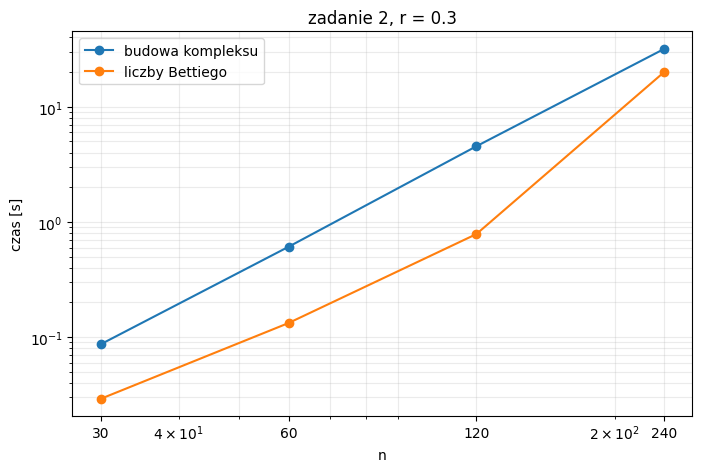

budowa  | nachylenie ze wszystkich: 2.85 | z n = 120, 240: 2.81
betti   | nachylenie ze wszystkich: 3.08 | z n = 120, 240: 4.67
f1      | nachylenie: 1.99
f2      | nachylenie: 2.99
f1 * f2 | nachylenie: 4.98   (rozmiar macierzy d2)


In [20]:
def nachylenie(ns, ts):
    return np.polyfit(np.log(ns), np.log(ts), 1)[0]

plt.figure(figsize=(8, 5))
plt.loglog(ns, t_bud, 'o-', label='budowa kompleksu')
plt.loglog(ns, t_bet, 'o-', label='liczby Bettiego')
plt.xlabel('n')
plt.ylabel('czas [s]')
plt.title('zadanie 2, r = 0.3')
plt.xticks(ns, ns)
plt.legend()
plt.grid(alpha=0.25, which='both')
plt.show()

for nazwa, ts in [('budowa', t_bud), ('betti', t_bet)]:
    print(f'{nazwa:7} | nachylenie ze wszystkich: {nachylenie(ns, ts):.2f} | z n = 120, 240: {nachylenie(ns[2:], ts[2:]):.2f}')
print(f'f1      | nachylenie: {nachylenie(ns, [fv[1] for fv in fy]):.2f}')
print(f'f2      | nachylenie: {nachylenie(ns, [fv[2] for fv in fy]):.2f}')
print(f'f1 * f2 | nachylenie: {nachylenie(ns, [fv[1] * fv[2] for fv in fy]):.2f}   (rozmiar macierzy d2)')

- budowa: nachylenie ok. 3 (3.05 ze wszystkich punktów, 2.95 z dwóch ostatnich), czyli $t \sim n^3$ i podwojenie $n$ wydłuża budowę ok. 8 razy
- liczby Bettiego: ze wszystkich punktów wychodzi 3.03, ale z dwóch ostatnich już 4.36, wykres wygina się w górę. $f_1 \sim n^2$ i $f_2 \sim n^3$ (nachylenia 1.99 i 2.99), więc gęsta macierz $\partial_2$ ma $f_1 \cdot f_2 \sim n^5$ wyrazów (nachylenie 4.98), a samo jej zbudowanie i zamiana na GF(2) dotyka każdego wyrazu. dla małych $n$ dominuje narzut, a dla większych nachylenie powinno zbliżać się do 5
- dla $n = 240$ betti jest jeszcze szybsze od budowy (10.9 s wobec 15.8 s), ale rośnie szybciej, więc dla większych $n$ to ono będzie wąskim gardłem

**zadanie 2b**

`cech` sprawdza wszystkie podzbiory co najwyżej 3-elementowe, niezależnie od $r$:
$$\binom{n}{1} + \binom{n}{2} + \binom{n}{3} = n + \frac{n(n-1)}{2} + \frac{n(n-1)(n-2)}{6} \approx \frac{n^3}{6}$$
dla każdego liczy $\rho$ w stałym czasie, więc czas budowy powinien rosnąć jak $n^3$. sprawdzam, czy czas na jeden podzbiór jest mniej więcej stały

In [21]:
podzbiory = [n + comb(n, 2) + comb(n, 3) for n in ns]
for n, ile, t in zip(ns, podzbiory, t_bud):
    print(f'n = {n:3} | podzbiory: {ile:8} | czas / podzbior: {t / ile * 1e6:.2f} mikrosekund')

n =  30 | podzbiory:     4525 | czas / podzbior: 19.16 mikrosekund
n =  60 | podzbiory:    36050 | czas / podzbior: 16.88 mikrosekund
n = 120 | podzbiory:   288100 | czas / podzbior: 15.76 mikrosekund
n = 240 | podzbiory:  2304200 | czas / podzbior: 13.80 mikrosekund


czas na jeden podzbiór jest stały, ok. 6-7 mikrosekund, więc czas budowy to (liczba podzbiorów) razy stała, czyli $\approx n^3 / 6$ razy stała. dla $n = 240$ prawie wszystkie podzbiory to trójki (2275280 z 2304200), a do kompleksu weszło z nich tylko 64015, czyli ok. 3%. reszta to sprawdzanie trójek punktów z różnych końców okręgu, o których od razu widać, że nie mają szans. $r$ nie ma tu znaczenia, co było widać w 1a

**zadanie 2c**

budowa: liczba podzbiorów razy czas na jeden podzbiór z $n = 240$

liczby Bettiego: ekstrapolacja $t(n) \approx t(240) \cdot (n / 240)^a$ z nachyleniem z dwóch ostatnich punktów. do tego sprawdzam pamięć: $f_1 \sim n^2$, $f_2 \sim n^3$ (przy stałym $r$ każdy punkt ma sąsiadów proporcjonalnie do $n$), a macierz brzegu $\partial_2$ jest gęsta, $f_1 \times f_2$ intów po 8 bajtów

In [22]:
na_podzbior = t_bud[-1] / podzbiory[-1]
a_bet = nachylenie(ns[2:], t_bet[2:])

for n in [1000, 10**4]:
    t_b = (n + comb(n, 2) + comb(n, 3)) * na_podzbior
    t_h = t_bet[-1] * (n / 240) ** a_bet
    f1 = fy[-1][1] * (n / 240) ** 2
    f2 = fy[-1][2] * (n / 240) ** 3
    print(f'n = {n:5} | budowa: {t_b:.2e} s = {t_b / 3600:.1f} h = {t_b / 86400:.1f} dni | '
          f'betti: {t_h:.2e} s = {t_h / 3600:.1f} h = {t_h / 86400:.1f} dni')
    print(f'          f1 ~ {f1:.1e}, f2 ~ {f2:.1e}, macierz d2: {f1 * f2 * 8 / 1e9:.1e} GB')

n =  1000 | budowa: 2.30e+03 s = 0.6 h = 0.0 dni | betti: 1.58e+04 s = 4.4 h = 0.2 dni
          f1 ~ 9.6e+04, f2 ~ 4.6e+06, macierz d2: 3.6e+03 GB
n = 10000 | budowa: 2.30e+06 s = 638.9 h = 26.6 dni | betti: 7.48e+08 s = 207694.8 h = 8654.0 dni
          f1 ~ 9.6e+06, f2 ~ 4.6e+09, macierz d2: 3.6e+08 GB


- $n = 1000$: budowa ok. 1140 s, czyli ok. 19 minut, da się poczekać. liczby Bettiego z ekstrapolacji ok. 1.5 h, ale to i tak nierealne, bo macierz $\partial_2$ miałaby ok. 96 tys. $\times$ 4.6 mln wyrazów, czyli ok. 3600 GB. tu ograniczeniem jest pamięć, a nie czas. do tego nachylenie 4.36 jeszcze rośnie w stronę 5, więc 1.5 h to raczej zaniżenie
- $n = 10^4$: budowa ok. 317 h, czyli ok. 13 dni, a liczby Bettiego ok. 1460 dni (4 lata) i $3.6 \cdot 10^8$ GB, bez szans
- oszacowaniu budowy ufam bardziej, bo czas na podzbiór był stały dla wszystkich $n$. przy betti ekstrapoluję z dwóch punktów, więc to tylko rząd wielkości

**zadanie 2d**

In [23]:
for n, b in zip(ns, bety):
    d = najdalszy_punkt_okregu(chmury[n])
    print(f'n = {n:3} | beta = {b} | najdalszy punkt okregu: {d:.3f} (r/2 = 0.15)')

n =  30 | beta = [1, 0] | najdalszy punkt okregu: 0.320 (r/2 = 0.15)
n =  60 | beta = [1, 1] | najdalszy punkt okregu: 0.183 (r/2 = 0.15)
n = 120 | beta = [1, 1] | najdalszy punkt okregu: 0.135 (r/2 = 0.15)
n = 240 | beta = [1, 1] | najdalszy punkt okregu: 0.084 (r/2 = 0.15)


**Wnioski do zadania 2**

- dla $n = 30$ wychodzi $\beta = (1, 0)$, czyli okręgu nie widać. najdalszy punkt okręgu jest 0.320 od chmury, czyli w próbce jest przerwa szeroka mniej więcej na $0.64 > 2r = 0.6$. żadna krawędź jej nie przeskakuje, pętla się nie zamyka i kompleks to jeden łuk (spójny, ściągalny)
- dla $n \ge 60$ wychodzi okrąg. dla $n = 120$ i $240$ najdalszy punkt okręgu jest bliżej niż $r/2 = 0.15$ i $r = 0.3 < 0.775$, czyli warunki z twierdzenia są spełnione (poza tym, że jest szum). dla $n = 60$ jest 0.183 > 0.15, czyli warunek gęstości nie zachodzi, a okrąg i tak wyszedł, znowu warunek wystarczający, a nie konieczny
- czyli nie zawsze wychodzi okrąg: przy ustalonym $r$ próbka musi być dostatecznie gęsta. punkty są losowe, więc przy małym $n$ łatwo o dużą przerwę. większe $n$ daje gęstszą próbkę i pewniejszy wynik, ale kosztuje $n^3$ przy budowie i jeszcze więcej przy liczbach Bettiego
- przy tym samym $r$ liczba sympleksów rośnie jak $n^2$ i $n^3$, a $\beta$ się nie zmienia od $n = 60$, więc przy dużych $n$ większość pracy idzie na sympleksy, które nic nie wnoszą do wyniku

##### **Zadanie 3**

pomysł z ostatniego slajdu wykładu 5: ściana sympleksu Čecha też jest w kompleksie, więc podzbiór ma sens sprawdzać tylko wtedy, gdy wszystkie jego ściany już są:
1. wierzchołki: wszystkie punkty
2. krawędzie: $\{i, j\}$, gdy $\|x_i - x_j\| < 2r$ (to to samo co $\rho < r$ dla krawędzi)
3. trójkąty: krawędź $\{i, j\}$, $i < j$, rozszerzam tylko o $k \in N^+(i) \cap N^+(j)$, gdzie $N^+(i)$ to sąsiedzi $i$ o większym numerze, i dopiero dla nich liczę $\rho$

wtedy $\{i, j\}, \{i, k\}, \{j, k\}$ są krawędziami, więc to dokładnie trójki, których wszystkie ściany są w kompleksie. $N^+(i)$ to etykiety dzieci węzła $i$ w drzewie sympleksów, tylko trzymam je sam w zbiorach, bo tak łatwiej robić przecięcia

In [24]:
def cech_szybki(X, r):
    n = len(X)
    st = gudhi.SimplexTree()
    for i in range(n):
        st.insert([i])

    # krawedzie i N+(i)
    sasiedzi = [set() for _ in range(n)]
    for i in range(n):
        for j in range(i + 1, n):
            if np.linalg.norm(X[i] - X[j]) < 2 * r:
                st.insert([i, j])
                sasiedzi[i].add(j)

    # trojkaty: kandydaci k z N+(i) i N+(j)
    for i in range(n):
        for j in sasiedzi[i]:
            for k in sasiedzi[i] & sasiedzi[j]:
                if rho(X[[i, j, k]]) < r:
                    st.insert([i, j, k])
    return st

sprawdzenie, czy wychodzą dokładnie te same kompleksy co w zadaniu 2 (porównuję listy wszystkich sympleksów)

In [25]:
for n in ns:
    K = cech_szybki(chmury[n], 0.3)
    takie_same = all(simplices(K, k) == simplices(kompleksy[n], k) for k in range(3))
    print(f'n = {n:3} | f = {K.num_simplices_by_dimension()} | te same sympleksy: {takie_same}')

n =  30 | f = [ 30  91 140] | te same sympleksy: True
n =  60 | f = [ 60 332 835] | te same sympleksy: True
n = 120 | f = [ 120 1433 8743] | te same sympleksy: True
n = 240 | f = [  240  5551 64015] | te same sympleksy: True


pomiary czasu budowy dla tych samych $n$. dodatkowo $n = 480$ i $960$: ograniczenie $n \le 240$ było przez macierze brzegu, a tu liczę tylko budowę, bez liczb Bettiego

In [26]:
ns3 = ns + [480, 960]
t_szyb, f2_szyb = [], []
for n in ns3:
    X = chmury[n] if n in chmury else chmura(n, 0.05)
    start = perf_counter()
    K = cech_szybki(X, 0.3)
    t_szyb.append(perf_counter() - start)
    f2_szyb.append(f(K, 2))
    print(f'n = {n:3} | f = {str(K.num_simplices_by_dimension()):24} | budowa: {t_szyb[-1]:.3f} s')

n =  30 | f = [ 30  91 140]            | budowa: 0.007 s
n =  60 | f = [ 60 332 835]            | budowa: 0.020 s
n = 120 | f = [ 120 1433 8743]         | budowa: 0.144 s
n = 240 | f = [  240  5551 64015]      | budowa: 1.016 s
n = 480 | f = [   480  22102 506026]   | budowa: 7.336 s
n = 960 | f = [    960   88632 4082483] | budowa: 62.165 s


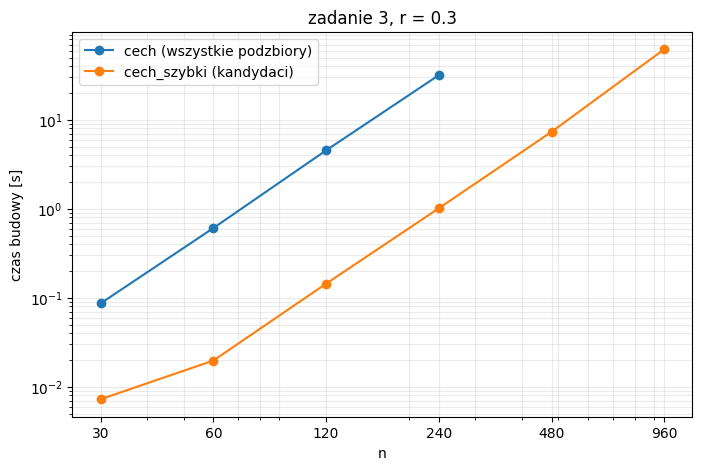

n =  30 ->  60 | nachylenie: 1.44
n =  60 -> 120 | nachylenie: 2.87
n = 120 -> 240 | nachylenie: 2.81
n = 240 -> 480 | nachylenie: 2.85
n = 480 -> 960 | nachylenie: 3.08
przyspieszenie dla n = 240: 31.3 razy


In [27]:
plt.figure(figsize=(8, 5))
plt.loglog(ns, t_bud, 'o-', label='cech (wszystkie podzbiory)')
plt.loglog(ns3, t_szyb, 'o-', label='cech_szybki (kandydaci)')
plt.xlabel('n')
plt.ylabel('czas budowy [s]')
plt.title('zadanie 3, r = 0.3')
plt.xticks(ns3, ns3)
plt.legend()
plt.grid(alpha=0.25, which='both')
plt.show()

for i in range(len(ns3) - 1):
    print(f'n = {ns3[i]:3} -> {ns3[i + 1]:3} | nachylenie: {nachylenie(ns3[i:i + 2], t_szyb[i:i + 2]):.2f}')
print(f'przyspieszenie dla n = 240: {t_bud[-1] / t_szyb[3]:.1f} razy')

żeby zrozumieć tempo, liczę ilu kandydatów na trójkąty sprawdza `cech_szybki`. to są trójki, w których każda para jest krawędzią, czyli trójkąty kompleksu flagowego grafu krawędzi (ekspansja z wykładu 2). porównuję z liczbą wszystkich trójek $\binom{n}{3}$ i z $f_2$, czyli z tym, ile trójkątów faktycznie jest w kompleksie Čecha

In [28]:
for n, f2 in zip(ns3, f2_szyb):
    X = chmury[n] if n in chmury else chmura(n, 0.05)
    G = gudhi.SimplexTree()
    for i, j in itertools.combinations(range(n), 2):
        if np.linalg.norm(X[i] - X[j]) < 2 * 0.3:
            G.insert([i, j])
    G.expansion(2)
    kandydaci = G.num_simplices_by_dimension()[2]
    print(f'n = {n:3} | kandydaci: {kandydaci:8} | wszystkie trojki: {comb(n, 3):9} | '
          f'kandydaci / trojki: {kandydaci / comb(n, 3):.3f} | odrzucone przez rho: {kandydaci - f2}')

n =  30 | kandydaci:      140 | wszystkie trojki:      4060 | kandydaci / trojki: 0.034 | odrzucone przez rho: 0
n =  60 | kandydaci:      835 | wszystkie trojki:     34220 | kandydaci / trojki: 0.024 | odrzucone przez rho: 0
n = 120 | kandydaci:     8743 | wszystkie trojki:    280840 | kandydaci / trojki: 0.031 | odrzucone przez rho: 0
n = 240 | kandydaci:    64018 | wszystkie trojki:   2275280 | kandydaci / trojki: 0.028 | odrzucone przez rho: 3
n = 480 | kandydaci:   506066 | wszystkie trojki:  18316960 | kandydaci / trojki: 0.028 | odrzucone przez rho: 40
n = 960 | kandydaci:  4082752 | wszystkie trojki: 146995520 | kandydaci / trojki: 0.028 | odrzucone przez rho: 269


**Wnioski do zadania 3**

- `cech_szybki` daje dokładnie te same kompleksy co `cech` dla wszystkich $n$
- dla $n = 240$ budowa trwa 0.55 s zamiast 15.8 s, czyli ok. 29 razy szybciej. dla $n = 960$ trwała 31 s, a naiwnie (liczba podzbiorów razy 6.86 mikrosekund z 2b) byłoby to ok. 1010 s, czyli ok. 17 minut
- dla małych $n$ czasy to milisekundy i nachylenia skaczą (1.69, 3.71, 2.00), ale od $n = 240$ wychodzi 2.90 i 2.91. czyli czas dalej rośnie jak $n^3$, zmieniła się tylko stała
- dlaczego dalej $n^3$: kandydatów na trójkąty jest ok. 2.8% wszystkich trójek i ten ułamek nie zmienia się z $n$. przy stałym $r$ sąsiedzi punktu to punkty z kawałka okręgu o stałej długości, więc jest ich proporcjonalnie do $n$, a kandydatów $\sim n \cdot n^2 = n^3$. przyspieszenie powinno być ok. $1 / 0.028 \approx 35$ razy, wyszło 29, bo dochodzą jeszcze pary ($\sim n^2$) i operacje na zbiorach
- prawie żaden kandydat nie odpada przez test $\rho$: 0, 0, 0, 3, 40, 269 na kilka milionów. punkty z krótkiego łuku są prawie na jednej prostej, trójkąt jest rozwartokątny i $\rho$ to połowa najdłuższego boku, a ta jest $< r$, bo każdy bok jest krawędzią. czyli tutaj Čech prawie pokrywa się z kompleksem flagowym (to jest Rips z wykładu 6, bez testu $\rho$) i `cech_szybki` sprawdza praktycznie tylko to, co i tak musi wstawić
- szybciej niż $n^3$ przy stałym $r$ się nie da: sam kompleks ma $f_2 \sim n^3$ trójkątów (nachylenie 2.99 w 2a), a każdy trzeba wstawić. przyspieszyć można tylko zmniejszając $r$ albo $n$
- teraz wąskim gardłem są liczby Bettiego, a nie budowa: dla $n = 960$ kompleks buduje się w pół minuty, ale gęsta macierz $\partial_2$ miałaby $88632 \times 4082483$ wyrazów, czyli ok. 2900 GB